<a href="https://colab.research.google.com/github/Razeefshaik/MEvsAI/blob/main/notebooks/gpt_build.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-11-01 19:41:14--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.110.133, 185.199.108.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.110.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  --.-KB/s    in 0.03s   

2026-11-01 19:41:14 (32.8 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [ ]:
with open('input.txt', 'r', encoding='utf-8') as f:
    text = f.read()

print("length of dataset in characters: ", len(text))

length of dataset in characters:  1115394


In [ ]:
print(text[:1000])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in thirst for revenge.



In [ ]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [ ]:
%pip install sentencepiece

In [ ]:
import sentencepiece as spm

spm.SentencePieceTrainer.train(
    input="input.txt",
    model_prefix="tiny_shakespeare_bpe",
    model_type="bpe",
    vocab_size=1024,
    character_coverage=1.0,
    byte_fallback=True,
    normalization_rule_name="identity",
    add_dummy_prefix=False,
    remove_extra_whitespaces=False,
    bos_id=-1,
    eos_id=-1,
    pad_id=-1,
    hard_vocab_limit=False
)

sp = spm.SentencePieceProcessor(
    model_file="tiny_shakespeare_bpe.model"
)

vocab_size = sp.get_piece_size()

encode = lambda s: sp.encode(s, out_type=int)
decode = lambda ids: sp.decode(ids)

In [ ]:
text_sample = "I love machine learning"

print(sp.encode(text_sample, out_type=str))
print(encode(text_sample))
print(decode(encode(text_sample)))

['I', '▁love', '▁ma', 'ch', 'ine', '▁l', 'ear', 'n', 'ing']
[980, 516, 929, 322, 449, 282, 408, 968, 299]
I love machine learning


In [ ]:
example = 'hii there!\nBefore we proceed.'
print('Text:   ', repr(example))
print('Pieces: ', sp.encode(example, out_type=str))
print('IDs:    ', encode(example))
print('Decoded:', repr(decode(encode(example))))
assert decode(encode(example)) == example

Text:    'hii there!\nBefore we proceed.'
Pieces:  ['hi', 'i', '▁there', '!', '<0x0A>', 'Be', 'fore', '▁we', '▁pro', 'ce', 'ed', '.']
IDs:     [371, 969, 500, 1005, 11, 771, 546, 331, 582, 309, 316, 984]
Decoded: 'hii there!\nBefore we proceed.'


In [ ]:
import torch
data= torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
print(data[:1000])

torch.Size([471698]) torch.int64
tensor([ 669,  419,  935,  983,   11,  771,  546,  331,  582,  309,  316,  799,
         272,  360,  711,  975,  670,  318,  614,  984,   11,   11,  985,  274,
         983,   11,  994,  982,  578,  975,  614,  984,   11,   11,  669,  419,
         935,  983,   11,  563,  418,  394,  353,  966,  492,  764,  612,  509,
         288,  277,  471,  525,  288,  272,  384,  554, 1003,   11,   11,  985,
         274,  983,   11,  993,  279,  492,  764,  984,  353,  966,  492,  764,
         984,   11,   11,  669,  419,  935,  983,   11,  669,  975,  289,  501,
         419,  964,  969,  387,  937,  574,  387,  324,  876,  718,  607,  479,
         974,  288,  268,  290,  961,  963,  798,  984,   11,   11,  985,  274,
         983,   11,  664,  501,  989,  962,  975,  331,  501,  989,  962,  984,
          11,   11,  669,  419,  935,  983,   11,  943,  528,  344,  333,  359,
         975,  297,  331,  989,  274,  354,  278,  654,  457,  411,  827,  290,
       

In [ ]:
n=int(0.9*len(data))
train_data= data[:n]
val_data= data[n:]

In [ ]:
block_size=128
train_data[: block_size+1]

tensor([ 669,  419,  935,  983,   11,  771,  546,  331,  582,  309,  316,  799,
         272,  360,  711,  975,  670,  318,  614,  984,   11,   11,  985,  274,
         983,   11,  994,  982,  578,  975,  614,  984,   11,   11,  669,  419,
         935,  983,   11,  563,  418,  394,  353,  966,  492,  764,  612,  509,
         288,  277,  471,  525,  288,  272,  384,  554, 1003,   11,   11,  985,
         274,  983,   11,  993,  279,  492,  764,  984,  353,  966,  492,  764,
         984,   11,   11,  669,  419,  935,  983,   11,  669,  975,  289,  501,
         419,  964,  969,  387,  937,  574,  387,  324,  876,  718,  607,  479,
         974,  288,  268,  290,  961,  963,  798,  984,   11,   11,  985,  274,
         983,   11,  664,  501,  989,  962,  975,  331,  501,  989,  962,  984,
          11,   11,  669,  419,  935,  983,   11,  943,  528])

In [ ]:
x = train_data[:block_size]
y = train_data[1:block_size+1]
for t in range(block_size):
    context = x[:t+1]
    target = y[t]
    print(f"when input is {context} the target: {target}")

when input is tensor([669]) the target: 419
when input is tensor([669, 419]) the target: 935
when input is tensor([669, 419, 935]) the target: 983
when input is tensor([669, 419, 935, 983]) the target: 11
when input is tensor([669, 419, 935, 983,  11]) the target: 771
when input is tensor([669, 419, 935, 983,  11, 771]) the target: 546
when input is tensor([669, 419, 935, 983,  11, 771, 546]) the target: 331
when input is tensor([669, 419, 935, 983,  11, 771, 546, 331]) the target: 582
when input is tensor([669, 419, 935, 983,  11, 771, 546, 331, 582]) the target: 309
when input is tensor([669, 419, 935, 983,  11, 771, 546, 331, 582, 309]) the target: 316
when input is tensor([669, 419, 935, 983,  11, 771, 546, 331, 582, 309, 316]) the target: 799
when input is tensor([669, 419, 935, 983,  11, 771, 546, 331, 582, 309, 316, 799]) the target: 272
when input is tensor([669, 419, 935, 983,  11, 771, 546, 331, 582, 309, 316, 799, 272]) the target: 360
when input is tensor([669, 419, 935, 98

In [ ]:
torch.manual_seed(1337)
batch_size= 4
block_size= 128

def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    return x, y

xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

for b in range(batch_size): # batch dimension
    for t in range(block_size): # time dimension
        context = xb[b, :t+1]
        target = yb[b,t]
        print(f"when input is {context.tolist()} the target: {target}")

inputs:
torch.Size([4, 128])
tensor([[ 278,  258,  772,  983,   11,  992,  961, 1015,  962,  288,  378,  507,
          297,  307,  289,  570,  695,  376,  975,  293,  989,  966,   11,  985,
          520,  481,  452,  288,  307,  632,  984,   11,   11, 1000,  428, 1001,
          363,  992,  990,  983,   11,  646,  289,  502,  575,  987,  528,  975,
           11,  664,  418,  339,  966,  960,  969,  989,  268,  303,  403,  280,
          983,  413,  989,  966,  457,  962,  465,  289,  500, 1003,   11,   11,
          760,  597,  883,  983,   11,  397,  339,  827,  269,  337,  966,  661,
          982,  606,  289,  983,  289,  989,  274,  305,  272,  569,  975,   11,
          771,  289,  269,  280,  961,  448,  268,  261,  987,  974,  984,   11,
          980,  464,  402,  979,  970,  299,  493,  975,   11,  636,  325,  289,
          831,  309,  472,  318,  321,  627,  292,  686],
        [ 268,  278,  721, 1003,   11,   11,  735,  459,  370, 1004,  370,  437,
          983,   11,  

In [ ]:
import torch
import torch.nn as nn
from torch.nn import functional as F
torch.manual_seed(1337)

class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # each token directly reads off the logits for the next token from a lookup table
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):

        # idx and targets are both (B,T) tensor of integers
        logits = self.token_embedding_table(idx) # (B,T,C)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        # idx is (B, T) array of indices in the current context
        for _ in range(max_new_tokens):
            # get the predictions
            logits, loss = self(idx)
            # focus only on the last time step
            logits = logits[:, -1, :] # becomes (B, C)
            # apply softmax to get probabilities
            probs = F.softmax(logits, dim=-1) # (B, C)
            # sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1) # (B, 1)
            # append sampled index to the running sequence
            idx = torch.cat((idx, idx_next), dim=1) # (B, T+1)
        return idx

m = BigramLanguageModel(vocab_size)
logits, loss = m(xb, yb)
print(logits.shape)
print(loss)

print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=100)[0].tolist()))


torch.Size([512, 1024])
tensor(7.3727, grad_fn=<NllLossBackward0>)
 ⁇ wn andGLOUC0ppreatward3oughau eBication� sh  G#ageORIOLANUS�GR ofByLO father thy;ieINio betOforrow atGINIUS MIf dayx where OF gracellberSecondershe g wife  such hast qugh ma honour h hadlesshan tw: t�INC�m GMENENIUSd comCome atldz f Mar wor( whatG YWek bear�& com thntSLEMEN much


In [ ]:
print(m.parameters())

<generator object Module.parameters at 0x7a68e4277bc0>


In [ ]:
optimizer= torch.optim.AdamW(m.parameters(), lr=1e-3)

In [ ]:

for steps in range(8000):
  xb, yb= get_batch('train')

  logits, loss= m(xb, yb)
  optimizer.zero_grad(set_to_none=True)
  loss.backward()
  optimizer.step()

print(loss.item())

4.186447620391846


In [ ]:
print(decode(m.generate(idx = torch.zeros((1, 1), dtype=torch.long), max_new_tokens=500)[0].tolist()))

 ⁇ oisespe officularot�ive?
WAlpeak� you childQUE A� cannot�j-ke?
The heartLetUMWhereDUs1 ragthly provings�ave no war unpetplainted her a sails we how now, ple well us any gentle ClESaveBA� on menhaIrok trst love of 't
And beg. I will prodone just did rep never@�ice oWho too sure"ENB parted lessar then as all spurn before�ond a

If grace who hath him falth it: prayLA beforeCORIOLANUSShe� done to dea:
though along theseide upon that you how time! but con nowct I curseGRran lamsLeachber�J unh our poor beingefear lookld have trano at F longoreonevot not, but ifRO may art
I's/yresher Y�ight�If Comeiltffusimq bringle, wery like ne po his lessOM up my tru.

I would thinkless as I was?

eperaid, bearYou should call heart they unl how it raCT very much begunLOio, you shall we no world yet

Thanc of great then in,
D seest part�nt:
ForARINAuishmar wory�gelway 't-dyonduy see them j�igh relinn before��RO] shall have mur memercate heaven"c with my father but it myselfLANUSel th give
And� theyeace

In [ ]:
m.eval()

prompt = "ROMEO:\n"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long
)

with torch.no_grad():
    generated = m.generate(
        idx=context,
        max_new_tokens=200
    )

print(decode(generated[0].tolist()))

ROMEO:
F pl then
Unt
M,whe Wever to at sure twICThat would beg�RENWICeak Hence speak myself exce that may keI breNowThe Dor
cent' should pure of heart;
ently
Since�Bockiftcal can shedwardSo fairSle to my abound spice� know it this ma'llen vily
The charUnce the prick chi�ven are, let her prawUM O(o speak am thusShe�ull tw vaupress of jay all for pl� rose did mety
And seemThat Cl}(+ight with him--FoundWould have wifeENTIO app mineull thoseBy lastood, come the ne count?
ButtheBUE cor;
'ComeWhy�ci�ie for hell rest,
NI


In [ ]:
train_data = data[:n]
val_data = data[n:]

In [ ]:
@torch.no_grad()
def evaluate(split, num_batches=100):
    m.eval()
    losses = []

    for _ in range(num_batches):
        xb, yb = get_batch(split)
        logits, loss = m(xb, yb)
        losses.append(loss.item())

    return sum(losses) / len(losses)


train_loss = evaluate('train')
val_loss = evaluate('val')

print(f"Training Loss:   {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

Training Loss:   4.0988
Validation Loss: 4.4697


In [ ]:
prompts = [
    "ROMEO:\n",
    "JULIET:\n",
    "KING:\n"
]

m.eval()

with torch.no_grad():
    for prompt in prompts:
        context = torch.tensor(
            [encode(prompt)],
            dtype=torch.long
        )

        output = m.generate(context, max_new_tokens=100)

        print("\nPROMPT:", repr(prompt))
        print(decode(output[0].tolist()))
        print("-" * 50)


PROMPT: 'ROMEO:\n'
ROMEO:
de
PE:
LE�ray on, cl u prys thee do gor, gra brother fearMy faremen�	 your vis8 lookers on poor der will much lSecond4rom my own seat unt_ their friends sir,
And ser?INCENTIOT< fearless wilt thou seenom in thy b��ife�� ridex
MORDec my appulate wo allers wings
--------------------------------------------------

PROMPT: 'JULIET:\n'
JULIET:
To part hand thusward shall IAN�8!Dokeer is po P these ra ab that must thy not stay rep+��GLOUCESTERassORs gmanher to Yhing rawent pll romanORIOad am not, heaastign how out  there� queenORK more cQenti'd in me=� or whe think?
W:
JUp and onward muchAB:
But with these offTGLOUC lookhe your
--------------------------------------------------

PROMPT: 'KING:\n'
KING:
What scurde before I fa��abondy of death�rurapulrude table and roy no friendENRY upon that go
Hereirst mean not but welow T heavenly and eyes�um beg�UCHIO wombighack props on your b heavenown'Buke is
D fri�These plLet twith; know you of st father Mones: as great

In [ ]:
prompts = [
    "The king is here.",
    "My dog is here."
]

m.eval()

for prompt in prompts:
    ids = encode(prompt)
    context = torch.tensor([ids], dtype=torch.long)

    with torch.no_grad():
        logits, _ = m(context)
        probs = F.softmax(logits[:, -1, :], dim=-1)

    print(prompt)
    print("Last token ID:", ids[-1])
    print("Most likely next token:", decode([probs.argmax().item()]))

The king is here.
Last token ID: 984
Most likely next token: 

My dog is here.
Last token ID: 984
Most likely next token: 



In [ ]:
# toy example illustrating how matrix multiplication can be used for a "weighted aggregation"
torch.manual_seed(42)
a = torch.tril(torch.ones(3, 3))
a = a / torch.sum(a, 1, keepdim=True)
b = torch.randint(0,10,(3,2)).float()
c = a @ b
print('a=')
print(a)
print('--')
print('b=')
print(b)
print('--')
print('c=')
print(c)

a=
tensor([[1.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000],
        [0.3333, 0.3333, 0.3333]])
--
b=
tensor([[2., 7.],
        [6., 4.],
        [6., 5.]])
--
c=
tensor([[2.0000, 7.0000],
        [4.0000, 5.5000],
        [4.6667, 5.3333]])


In [ ]:
# version 4: self-attention!
torch.manual_seed(1337)
B,T,C = 4,8,32 # batch, time, channels
x = torch.randn(B,T,C)

# let's see a single Head perform self-attention
head_size = 16
key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)
k = key(x)   # (B, T, 16)
q = query(x) # (B, T, 16)
wei =  q @ k.transpose(-2, -1) # (B, T, 16) @ (B, 16, T) ---> (B, T, T)

tril = torch.tril(torch.ones(T, T))
#wei = torch.zeros((T,T))
wei = wei.masked_fill(tril == 0, float('-inf'))
wei = F.softmax(wei, dim=-1)

v = value(x)
out = wei @ v
#out = wei @ x

out.shape

torch.Size([4, 8, 16])



```
 GPT
 ├── Token Embedding
 ├── Position Embedding
 ├── Block 1
 │    ├── MultiHeadAttention
 │    │    ├── Head 1
 │    │    ├── Head 2
 │    │    ├── Head 3
 │    │    └── Head 4
 │    ├── FeedFoward
 │    └── LayerNorm
 ├── Block 2
 ├── Block 3
 ├── Block 4
 ├── Final LayerNorm
 └── Language Modeling Head
```



In [ ]:
import math

@torch.no_grad()
def evaluate_model(model, num_batches=100, seed=42):
    was_training = model.training
    model.eval()

    results = {}

    for split in ['train', 'val']:
        data = train_data if split == 'train' else val_data

        # Separate random generator for reproducible evaluation
        rng = torch.Generator().manual_seed(seed)

        total_loss = 0.0
        total_tokens = 0

        for _ in range(num_batches):
            ix = torch.randint(
                len(data) - block_size,
                (batch_size,),
                generator=rng
            )

            x = torch.stack([
                data[i:i+block_size] for i in ix
            ]).to(device)

            y = torch.stack([
                data[i+1:i+block_size+1] for i in ix
            ]).to(device)

            logits, loss = model(x, y)

            token_count = y.numel()
            total_loss += loss.item() * token_count
            total_tokens += token_count

        avg_loss = total_loss / total_tokens

        results[split] = {
            "loss": avg_loss,
            "perplexity": math.exp(avg_loss)
        }

    model.train(was_training)
    return results

Device: cuda
Dataset characters: 1115394
Vocabulary size: 1024
Training tokens: 424528
Validation tokens: 47170
Model parameters: 1.467 M
Step     0 | Train: 6.9811 | Val: 6.9582 | Val PPL: 1051.70 | LR: 0.000300
  New best checkpoint saved!
Step   200 | Train: 5.1846 | Val: 5.1706 | Val PPL: 176.02 | LR: 0.000300
  New best checkpoint saved!
Step   400 | Train: 4.5239 | Val: 4.5996 | Val PPL: 99.45 | LR: 0.000299
  New best checkpoint saved!
Step   600 | Train: 4.2311 | Val: 4.3548 | Val PPL: 77.85 | LR: 0.000299
  New best checkpoint saved!
Step   800 | Train: 4.0731 | Val: 4.2528 | Val PPL: 70.30 | LR: 0.000298
  New best checkpoint saved!
Step  1000 | Train: 3.9678 | Val: 4.1338 | Val PPL: 62.42 | LR: 0.000297
  New best checkpoint saved!
Step  1200 | Train: 3.8863 | Val: 4.0720 | Val PPL: 58.67 | LR: 0.000295
  New best checkpoint saved!
Step  1400 | Train: 3.8149 | Val: 4.0232 | Val PPL: 55.88 | LR: 0.000294
  New best checkpoint saved!
Step  1600 | Train: 3.7580 | Val: 3.9702 | 

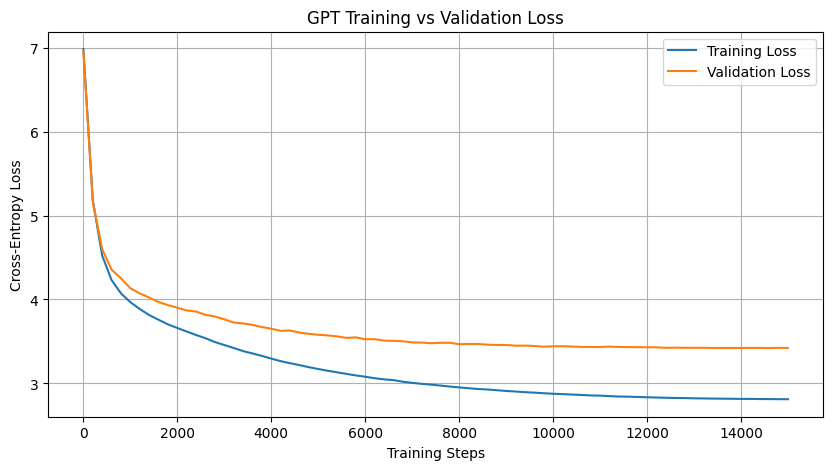

Best checkpoint step: 14600
Best validation loss: 3.4208671474456787
train | Loss: 2.8134 | Perplexity: 16.67
val | Loss: 3.4209 | Perplexity: 30.60

========== GENERATED TEXT ==========

ROMEO:
True, whose women Marcius is a braces to my love
were of her tears, yet I would not show
weal upon my justice and guilty.'

FLORIZEL:

CLARENCE:
Condemn'd,
You shall have, but not to fly.

ROMEO:
Nay, I'll say you, behority!

ROMEO:
He's dead, and he is the other.

FRIAR LAURENCE:
Why, my lord, I have gone, woever,
If they are so, that I have, to make
As much posterately. Aufidius, I saw my hours.

ROMEO:
Sir, gentle sir, my liege, I am done:
And I'll be so, though Mowbray's death,
That studest thou liest in this saltle
In strengths, the stock'st hours to be
Are I fourish'd upon my house; and then I'll swear it.

Nurse:
Nay, my lord:
Sir, I will nothing speak it?

JULIET:
I am so, 'tis no cousin, we'll traitor'd in
To fightly. What's that did commend the earth
That weeds have made his taunts wi

In [ ]:

import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import sentencepiece as spm
import matplotlib.pyplot as plt

# ============================================================
# 1. HYPERPARAMETERS
# ============================================================

batch_size = 16
block_size = 128
max_iters = 15000
eval_interval = 200
eval_iters = 100

learning_rate = 3e-4
min_learning_rate = 1e-5

n_embd = 128
n_head = 4
n_layer = 6
dropout = 0.1

device = "cuda" if torch.cuda.is_available() else "cpu"
checkpoint_path = "best_gpt_128d_6layer.pt"
tokenizer_path = "tiny_shakespeare_bpe.model"

torch.manual_seed(1337)

print("Device:", device)


# ============================================================
# 2. LOAD DATASET
# ============================================================

if not os.path.exists("input.txt"):
    import urllib.request

    url = (
        "https://raw.githubusercontent.com/karpathy/"
        "char-rnn/master/data/tinyshakespeare/input.txt"
    )
    urllib.request.urlretrieve(url, "input.txt")

with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

print("Dataset characters:", len(text))


# ============================================================
# 3. BPE TOKENIZATION
# ============================================================

# Reuse the existing tokenizer for fair comparison.
# Only train a new tokenizer if the file is missing.

if not os.path.exists(tokenizer_path):
    print("Training a new BPE tokenizer...")

    spm.SentencePieceTrainer.train(
        input="input.txt",
        model_prefix="tiny_shakespeare_bpe",
        model_type="bpe",
        vocab_size=1024,
        character_coverage=1.0,
        byte_fallback=True,
        normalization_rule_name="identity",
        add_dummy_prefix=False,
        remove_extra_whitespaces=False,
        bos_id=-1,
        eos_id=-1,
        pad_id=-1,
        hard_vocab_limit=False,
        minloglevel=2
    )

sp = spm.SentencePieceProcessor(
    model_file=tokenizer_path
)

vocab_size = sp.get_piece_size()

def encode(s):
    return sp.encode(s, out_type=int)

def decode(ids):
    return sp.decode(ids)

print("Vocabulary size:", vocab_size)

data = torch.tensor(
    encode(text),
    dtype=torch.long
)

# Same token-level split as the original notebook
n = int(0.9 * len(data))

train_data = data[:n]
val_data = data[n:]

print("Training tokens:", len(train_data))
print("Validation tokens:", len(val_data))


# ============================================================
# 4. BATCH GENERATION
# ============================================================

def get_batch(split):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - block_size,
        (batch_size,)
    )

    x = torch.stack([
        source[i:i + block_size] for i in ix
    ])

    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in ix
    ])

    return x.to(device), y.to(device)


# ============================================================
# 5. REPRODUCIBLE EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_model(model, num_batches=eval_iters, seed=42):
    was_training = model.training
    model.eval()

    results = {}

    for split_idx, split in enumerate(["train", "val"]):
        source = train_data if split == "train" else val_data

        rng = torch.Generator().manual_seed(seed + split_idx)

        total_loss = 0.0
        total_tokens = 0

        for _ in range(num_batches):
            ix = torch.randint(
                len(source) - block_size,
                (batch_size,),
                generator=rng
            )

            x = torch.stack([
                source[i:i + block_size] for i in ix
            ]).to(device)

            y = torch.stack([
                source[i + 1:i + block_size + 1] for i in ix
            ]).to(device)

            _, loss = model(x, y)

            count = y.numel()
            total_loss += loss.item() * count
            total_tokens += count

        avg_loss = total_loss / total_tokens

        results[split] = {
            "loss": avg_loss,
            "perplexity": math.exp(avg_loss)
        }

    model.train(was_training)
    return results


# ============================================================
# 6. SINGLE SELF-ATTENTION HEAD
# ============================================================

class Head(nn.Module):

    def __init__(self, head_size):
        super().__init__()

        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer(
            "tril",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)
        v = self.value(x)

        # Correct scaling: divide by sqrt(head_size)
        wei = (
            q @ k.transpose(-2, -1)
        ) * (k.shape[-1] ** -0.5)

        # Causal masking
        wei = wei.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)

        out = wei @ v

        return out


# ============================================================
# 7. MULTI-HEAD ATTENTION
# ============================================================

class MultiHeadAttention(nn.Module):

    def __init__(self, num_heads, head_size):
        super().__init__()

        self.heads = nn.ModuleList([
            Head(head_size) for _ in range(num_heads)
        ])

        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat(
            [h(x) for h in self.heads],
            dim=-1
        )

        return self.dropout(self.proj(out))


# ============================================================
# 8. FEED-FORWARD NETWORK
# ============================================================

class FeedForward(nn.Module):

    def __init__(self, n_embd):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


# ============================================================
# 9. TRANSFORMER BLOCK
# ============================================================

class Block(nn.Module):

    def __init__(self, n_embd, n_head):
        super().__init__()

        assert n_embd % n_head == 0

        head_size = n_embd // n_head

        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)

        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


# ============================================================
# 10. COMPLETE GPT MODEL
# ============================================================

class GPTLanguageModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.token_embedding_table = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding_table = nn.Embedding(
            block_size, n_embd
        )

        self.blocks = nn.Sequential(
            *[
                Block(n_embd, n_head)
                for _ in range(n_layer)
            ]
        )

        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        tok_emb = self.token_embedding_table(idx)

        pos_emb = self.position_embedding_table(
            torch.arange(T, device=idx.device)
        )

        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)

        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            B, T, C = logits.shape

            flat_logits = logits.reshape(B * T, C)
            flat_targets = targets.reshape(B * T)

            loss = F.cross_entropy(
                flat_logits,
                flat_targets
            )

        return logits, loss

    @torch.no_grad()
    def generate(
        self,
        idx,
        max_new_tokens,
        temperature=0.8,
        top_k=40
    ):
        if temperature <= 0:
            raise ValueError("Temperature must be positive.")

        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]

            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]

            # Temperature scaling
            logits = logits / temperature

            # Top-k filtering
            if top_k is not None:
                if top_k < 1:
                    raise ValueError("top_k must be >= 1.")

                k = min(top_k, logits.size(-1))

                values, _ = torch.topk(logits, k)

                cutoff = values[:, -1].unsqueeze(-1)

                logits = logits.masked_fill(
                    logits < cutoff,
                    float("-inf")
                )

            probs = F.softmax(logits, dim=-1)

            idx_next = torch.multinomial(
                probs,
                num_samples=1
            )

            idx = torch.cat((idx, idx_next), dim=1)

        return idx


# ============================================================
# 11. INITIALIZE A FRESH MODEL
# ============================================================

model = GPTLanguageModel().to(device)

num_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Model parameters: {num_params / 1e6:.3f} M")


# ============================================================
# 12. OPTIMIZER AND LEARNING-RATE SCHEDULER
# ============================================================

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=max_iters,
    eta_min=min_learning_rate
)

best_val_loss = float("inf")
history = []


# ============================================================
# 13. TRAINING LOOP — FRESH START
# ============================================================

model.train()

for step in range(max_iters):

    # Sample batch
    xb, yb = get_batch("train")

    # Forward propagation
    logits, loss = model(xb, yb)

    # Reset gradients
    optimizer.zero_grad(set_to_none=True)

    # Backpropagation
    loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    # Parameter update
    optimizer.step()

    # Learning-rate update
    scheduler.step()

    # Periodic evaluation
    if step % eval_interval == 0 or step == max_iters - 1:

        metrics = evaluate_model(model)

        train_loss = metrics["train"]["loss"]
        val_loss = metrics["val"]["loss"]

        train_ppl = metrics["train"]["perplexity"]
        val_ppl = metrics["val"]["perplexity"]

        current_lr = scheduler.get_last_lr()[0]

        history.append({
            "step": step,
            "train_loss": train_loss,
            "val_loss": val_loss,
            "train_ppl": train_ppl,
            "val_ppl": val_ppl,
            "lr": current_lr
        })

        print(
            f"Step {step:5d} | "
            f"Train: {train_loss:.4f} | "
            f"Val: {val_loss:.4f} | "
            f"Val PPL: {val_ppl:.2f} | "
            f"LR: {current_lr:.6f}"
        )

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss

            torch.save({
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "step": step,
                "val_loss": val_loss,
                "config": {
                    "vocab_size": vocab_size,
                    "batch_size": batch_size,
                    "block_size": block_size,
                    "n_embd": n_embd,
                    "n_head": n_head,
                    "n_layer": n_layer,
                    "dropout": dropout
                }
            }, checkpoint_path)

            print("  New best checkpoint saved!")


# ============================================================
# 14. PLOT TRAINING RESULTS
# ============================================================

steps = [h["step"] for h in history]

train_losses = [
    h["train_loss"] for h in history
]

val_losses = [
    h["val_loss"] for h in history
]

plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    train_losses,
    label="Training Loss"
)

plt.plot(
    steps,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")
plt.title("GPT Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


# ============================================================
# 15. LOAD THE BEST MODEL
# ============================================================

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best checkpoint step:", checkpoint["step"])
print("Best validation loss:", checkpoint["val_loss"])


# ============================================================
# 16. FINAL EVALUATION
# ============================================================

final_metrics = evaluate_model(model)

for split, metrics in final_metrics.items():
    print(
        f"{split} | "
        f"Loss: {metrics['loss']:.4f} | "
        f"Perplexity: {metrics['perplexity']:.2f}"
    )


# ============================================================
# 17. GENERATE TEXT
# ============================================================

prompt = "ROMEO:\n"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

model.eval()

with torch.no_grad():
    generated = model.generate(
        context,
        max_new_tokens=500,
        temperature=0.8,
        top_k=40
    )

print("\n========== GENERATED TEXT ==========\n")
print(decode(generated[0].tolist()))


In [ ]:
model.load_state_dict(
    torch.load(
        "best_gpt.pt",
        map_location=device,
        weights_only=True
    )["model_state_dict"]
)

model.eval()

prompt = "ROMEO:\n"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

output = model.generate(
    context,
    max_new_tokens=300,
    temperature=0.5,
    top_k=40
)

print(decode(output[0].tolist()))

ROMEO:
I have no more of such a power of all?

ROMEO:
I am a minister: but I saw thee,
Make the back of my glory,
And die in the minister of thy banishment,
And thou hast a cursed in my tired in thy father's virtuous
To make thy death, and I'll make
To breathe that I die to a bawd:
I am not a returning; and I am not
To make thy triumphood, with a voices,
And that I have revenged,
And, and by the bright of her duke's power.

KING HENRY VI:
Mark of Warwick, he will not,
To pale with the sleeping of our galling,
And make the duke and his boy's business,
And make thy faced, we'll speak it in the world
His peace of the first to a chase;
For all the fin of thy foul wrongs are set down.

KING HENRY VI:
O, I wish me, my lord of York!




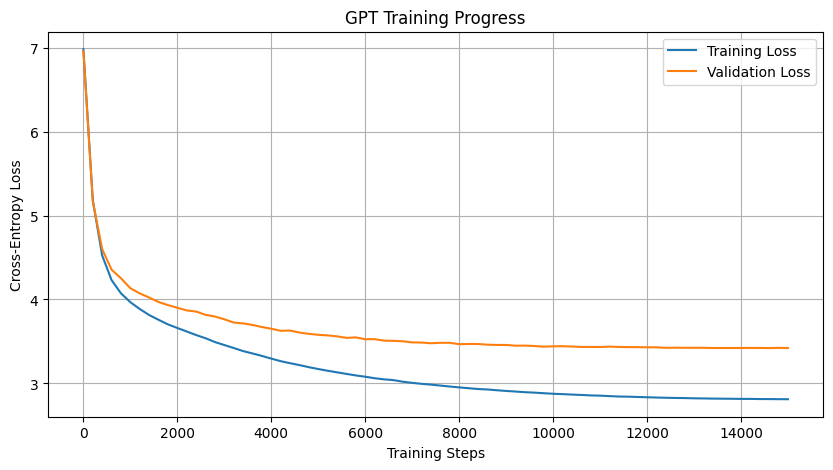

In [ ]:
import matplotlib.pyplot as plt

steps = [h['step'] for h in history]
train_losses = [h['train_loss'] for h in history]
val_losses = [h['val_loss'] for h in history]

plt.figure(figsize=(10, 5))

plt.plot(steps, train_losses, label='Training Loss')
plt.plot(steps, val_losses, label='Validation Loss')

plt.xlabel('Training Steps')
plt.ylabel('Cross-Entropy Loss')
plt.title('GPT Training Progress')

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
results = evaluate_model(model)

for split, metrics in results.items():
    print(
        f"{split}: "
        f"loss={metrics['loss']:.4f}, "
        f"perplexity={metrics['perplexity']:.2f}"
    )

train: loss=3.0676, perplexity=21.49
val: loss=3.5144, perplexity=33.60


In [ ]:
@torch.no_grad()
def generate_sample(model, prompt, max_new_tokens=100):
    model.eval()

    context = torch.tensor(
        [encode(prompt)],
        dtype=torch.long,
        device=device
    )

    output = model.generate(
        context,
        max_new_tokens=max_new_tokens
    )

    return decode(output[0].tolist())


print(generate_sample(model, "ROMEO:\n"))

ROMEO:
I hope him in the duke be
semour bringed, that wretched.

DUKE OF YORK:
Why thou art a why, what I have,
As I do not be.

DUKE OF YORK:
Show, I'll be the house of York;
Romeo to fond norture is bondure to
show us, every home


In [ ]:
model.eval()

prompt = "ROMEO:\n"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

for temperature in [0.6, 0.8, 1.0]:

    torch.manual_seed(42)

    with torch.no_grad():
        output = model.generate(
            context,
            max_new_tokens=200,
            temperature=temperature,
            top_k=40
        )

    print(f"\n{'='*20}")
    print(f"TEMPERATURE = {temperature}")
    print(f"{'='*20}\n")

    print(decode(output[0].tolist()))


TEMPERATURE = 0.6

ROMEO:
We will be people:
The people is the city wake against the guard,
Reven for our dukefuls,
To use my tidings.

FRIAR LAURENCE:
Ah, but, that's peace.

BAGARET:
Herset the passs, let's last,
And so I triumphants of England:
I have a tent, and I am he is not
More than the high since to be gone and times,
And, to use it in thy faults, and through.

GLOUCESTER:
But, to make a set down, when I'll put you.
I will not know it well beauty.

GLOUCESTER:


TEMPERATURE = 0.8

ROMEO:
We will be but help
The king to be a certer.

HORTENSIO:
Has you have no time the right, he is,
Ah'd your coward: your will's best
That you are broke to dance;
His light itself again, my lord.

EXTON:
Helm in the earth!

EXTANIO:
Thou shalt not:
Why, a women, sir, young sir, I'll be
From since to be a woe, in a valiant?

HORTENSIO:
Sir, you are well, I shall a traitor'd it so:
I cannot, and I have no drun, when you are not to be die.

P

TEMPERATURE = 1.0

ROMEO:
We will be but help
The king 